# Robustness Noise Viewer

Preview pixel-noise/effect overlays before generating the full robustness set.

In [ ]:
from pathlib import Path
import csv
import sys

import cv2
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('tests').resolve()))

from prepare_robustness_test import (
    apply_overlay,
    apply_pixel_patch,
    build_hand_pixel_patch,
    build_pixel_patch,
    read_overlay,
    raw_hand_path_for_video,
    safe_stem,
    write_augmented_video,
)

DATASET_DIR = Path('Dataset')
CSV_PATH = DATASET_DIR / 'split' / 'robustness_test.csv'
NOISE_DIR = DATASET_DIR / 'noise'
SOURCE_DIRS = [DATASET_DIR / 'raw', DATASET_DIR / 'testing']
PREVIEW_DIR = DATASET_DIR / 'robustness_noise' / 'preview'

VARIANT = 'pixel1'  # pixel1..pixel5 or effect1..effect5
ALPHA = 1.0
PIXEL_MIN_SCALE = 0.30
PIXEL_MAX_SCALE = 0.48
PIXEL_CENTER_JITTER = 0.18
PIXEL_PLACEMENT = 'hand'  # hand or center
PIXEL_HAND_SCALE = 1.45
PIXEL_NOISE_MIN_DURATION_FRAMES = 24
PIXEL_NOISE_MAX_DURATION_FRAMES = 36
SEED = 128
ROW_INDEX = 0
FRAME_INDEX = 0

In [ ]:
with CSV_PATH.open('r', encoding='utf-8-sig', newline='') as handle:
    rows = list(csv.DictReader(handle))

available_variants = sorted(path.stem for path in NOISE_DIR.glob('*.png'))
print(f'rows: {len(rows):,}')
print('variants:', ', '.join(available_variants))
rows[ROW_INDEX]

rows: 13,012
variants: effect1, effect2, effect3, effect4, effect5, pixel1, pixel2, pixel3, pixel4, pixel5


{'Participant ID': 'P42',
 'Video file': '023931338852502426-1 DOLLAR.mp4',
 'Gloss': '1DOLLAR',
 'ASL-LEX Code': 'C_02_025',
 'Participant ID_sd': 'P42',
 'Participant ID_si': 'P42',
 'Gloss_sd': '1DOLLAR',
 'Gloss_si': '1DOLLAR',
 'ASL-LEX Code_sd': 'C_02_025',
 'ASL-LEX Code_si': 'C_02_025',
 'same_gloss_sd_si': 'True',
 'same_asl_lex_code_sd_si': 'True',
 'has_10frame_hand': 'True',
 'has_20frame_hand': 'True',
 'has_30frame_hand': 'True',
 'skeleton_file': '023931338852502426-1 DOLLAR.npy'}

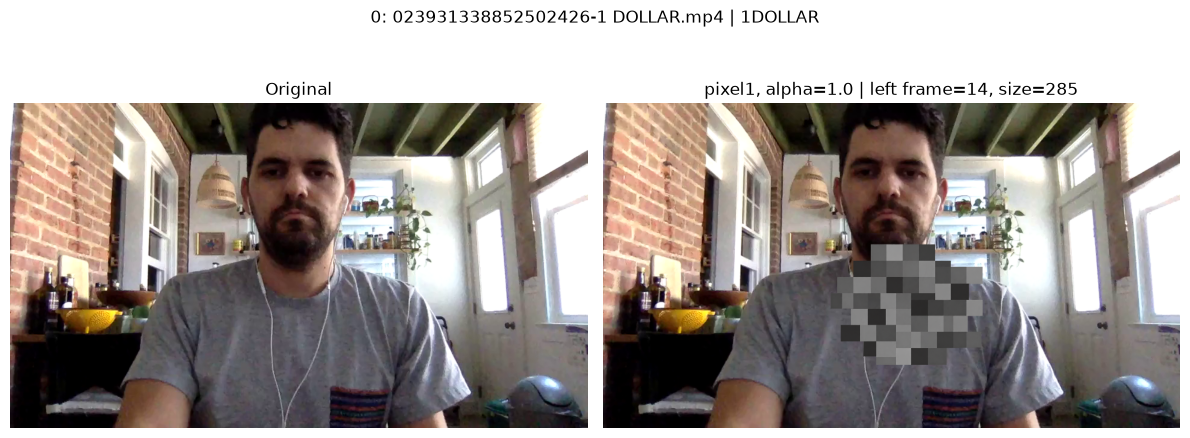

In [ ]:
def find_source(video_file):
    for source_dir in SOURCE_DIRS:
        candidate = source_dir / video_file
        if candidate.exists():
            return candidate
    raise FileNotFoundError(video_file)

def read_frame(video_path, frame_index=0):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise FileNotFoundError(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise ValueError(f'Could not read frame {frame_index} from {video_path}')
    return frame

row = rows[ROW_INDEX]
source_video = find_source(row['Video file'])
overlay_bgr, overlay_alpha = read_overlay(NOISE_DIR / f'{VARIANT}.png')
frame = read_frame(source_video, FRAME_INDEX)
if VARIANT.startswith('pixel'):
    import random
    rng = random.Random(SEED + ROW_INDEX)
    patch = None
    if PIXEL_PLACEMENT == 'hand':
        patch = build_hand_pixel_patch(
            hand_path=raw_hand_path_for_video(DATASET_DIR, row['Video file']),
            width=frame.shape[1],
            height=frame.shape[0],
            rng=rng,
            min_scale=PIXEL_MIN_SCALE,
            max_scale=PIXEL_MAX_SCALE,
            hand_scale=PIXEL_HAND_SCALE,
        )
    if patch is None:
        patch = build_pixel_patch(
            width=frame.shape[1],
            height=frame.shape[0],
            rng=rng,
            min_scale=PIXEL_MIN_SCALE,
            max_scale=PIXEL_MAX_SCALE,
            center_jitter=PIXEL_CENTER_JITTER,
        )
    augmented = apply_pixel_patch(frame, overlay_bgr, overlay_alpha, 1.0, patch)
    patch_label = f'{patch.target_hand} frame={patch.target_frame}, size={patch.size}'
else:
    patch = None
    augmented = apply_overlay(frame, overlay_bgr, overlay_alpha, ALPHA)
    patch_label = 'full frame effect'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original')
axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(augmented, cv2.COLOR_BGR2RGB))
effective_alpha = 1.0 if VARIANT.startswith('pixel') else ALPHA
axes[1].set_title(f'{VARIANT}, alpha={effective_alpha} | {patch_label}')
axes[1].axis('off')
fig.suptitle(f"{ROW_INDEX}: {row['Video file']} | {row['Gloss']}")
plt.tight_layout()

In [ ]:
preview_path = PREVIEW_DIR / VARIANT / f"{safe_stem(row['Video file'])}__{VARIANT}__a{ALPHA:.2f}.mp4"
metadata = write_augmented_video(
    source_path=source_video,
    output_path=preview_path,
    variant=type('Variant', (), {'name': VARIANT, 'path': NOISE_DIR / f'{VARIANT}.png'})(),
    alpha=ALPHA,
    codec='mp4v',
    seed=SEED + ROW_INDEX,
    dataset_dir=DATASET_DIR,
    video_file=row['Video file'],
    pixel_min_scale=PIXEL_MIN_SCALE,
    pixel_max_scale=PIXEL_MAX_SCALE,
    pixel_center_jitter=PIXEL_CENTER_JITTER,
    pixel_placement=PIXEL_PLACEMENT,
    pixel_hand_scale=PIXEL_HAND_SCALE,
    noise_min_duration_frames=PIXEL_NOISE_MIN_DURATION_FRAMES,
    noise_max_duration_frames=PIXEL_NOISE_MAX_DURATION_FRAMES,
)
print(preview_path)
metadata

Dataset/robustness_noise/preview/pixel1/023931338852502426-1_DOLLAR__pixel1__a1.00.mp4


{'fps': 30.0,
 'width': 960,
 'height': 540,
 'source_frame_count': 45,
 'written_frame_count': 45,
 'noise_mode': 'pixel_patch',
 'effective_alpha': 1.0,
 'pixel_patch_x': 362,
 'pixel_patch_y': 198,
 'pixel_patch_size': 285,
 'pixel_patch_center_x': 505,
 'pixel_patch_center_y': 341,
 'pixel_target_frame': 14,
 'pixel_target_frame_count': 30,
 'pixel_target_hand': 'left',
 'noise_start_frame': 6,
 'noise_end_frame': 35,
 'noise_duration_frames': 29}

After choosing settings, generate a small batch first:

```bash
docker exec gpu_ai_dev_env python /app/tests/prepare_robustness_test.py --generation-mode combined --variants all --assignment random --alpha 1.0 --pixel-placement hand --pixel-min-scale 0.30 --pixel-max-scale 0.48 --pixel-center-jitter 0.18 --noise-min-duration-frames 24 --noise-max-duration-frames 36 --limit 20
```

Generate one combined effect+pixel noisy video for every CSV row:

```bash
docker exec gpu_ai_dev_env python /app/tests/prepare_robustness_test.py --generation-mode combined --variants all --assignment random --alpha 1.0 --pixel-placement hand --pixel-min-scale 0.30 --pixel-max-scale 0.48 --pixel-center-jitter 0.18 --noise-min-duration-frames 24 --noise-max-duration-frames 36
```

Generate every effect+pixel combination for every CSV row:

```bash
docker exec gpu_ai_dev_env python /app/tests/prepare_robustness_test.py --generation-mode combined --variants all --assignment all --alpha 1.0 --pixel-placement hand --pixel-min-scale 0.30 --pixel-max-scale 0.48 --pixel-center-jitter 0.18 --noise-min-duration-frames 24 --noise-max-duration-frames 36
```